# **Deep Learning Lab Assignment 6**

**Team 17:** Mirthula M (26120121), Karthikeyan M (26120004)

Sentiment classification and image captioning using PyTorch. Both models use a single-layer RNN with 64 hidden units and GloVe 50-dimensional word embeddings. Run from the `lab6/` directory.

## **1. Imports and setup**

In [1]:
import copy
import html
import random
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from torchvision.models import vgg16, VGG16_Weights
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from nltk.translate.bleu_score import corpus_bleu

SEED = 17
torch.set_num_threads(4)

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

set_seed()
plt.rcParams['figure.dpi'] = 100
DATA = Path('./data/team17')

## **2. Read and prepare the sentiment data**

Keep the supplied test split and labels unchanged. Remove normalized-text test overlaps and duplicates from training, then use grouped validation. The data are strongly imbalanced.

In [2]:
train_df = pd.read_csv('./data/team17/sentiment/train.csv')
test_df = pd.read_csv('./data/team17/sentiment/test.csv')
display(train_df.head())
pd.DataFrame({'Train': train_df.sentiment.value_counts(), 'Test': test_df.sentiment.value_counts()})

,id,sentiment,tweet
0,25493,Negative,@user what if obama showed the same anger and...
1,16074,Negative,happy day! #altwaystoheal #healthy
2,4760,Negative,peace of mind #serenity
3,27164,Negative,how to create the life you want #success #lif...
4,6444,Negative,take me back. #chicago #selfie missing my fami...


,Train,Test
sentiment,,
Negative,5195,1295
Positive,405,105


In [3]:
TOKEN_PATTERN = re.compile(r"<url>|<user>|#?[^\W_]+(?:['’][^\W_]+)*|[^\w\s]", re.UNICODE)

def normalize(text):
    """Conservative exact-match key; do not remove punctuation or user names."""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", html.unescape(text)).casefold()).strip()

def tokenize(text):
    text = normalize(text)
    text = re.sub(r"https?://\S+|www\.\S+", " <url> ", text)
    text = re.sub(r"@\w+", " <user> ", text)
    return [token.lstrip("#").replace("’", "'") for token in TOKEN_PATTERN.findall(text)]

In [4]:
label_ids = {'Negative': 0, 'Positive': 1}
for frame in (train_df, test_df):
    frame['key'] = frame.tweet.map(normalize)
    frame['tokens'] = frame.tweet.map(tokenize)
    frame['label'] = frame.sentiment.map(label_ids)

clean_train = train_df[~train_df.key.isin(test_df.key)].drop_duplicates(['key', 'label']).reset_index(drop=True)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fit_indices, val_indices = next(splitter.split(clean_train, clean_train.label, clean_train.key))
sent_fit = clean_train.iloc[fit_indices]
sent_val = clean_train.iloc[val_indices]

counts = Counter(word for tokens in sent_fit.tokens for word in tokens)
sent_special = ['<pad>', '<unk>', '<user>', '<url>']
sent_vocab = {word: i for i, word in enumerate(sent_special)}
for word, count in counts.most_common():
    if count >= 2 and word not in sent_vocab:
        sent_vocab[word] = len(sent_vocab)

assert not set(sent_fit.key) & set(sent_val.key)
assert not set(clean_train.key) & set(test_df.key)
print(f'Fit/validation/test rows: {len(sent_fit)}/{len(sent_val)}/{len(test_df)}')
print(f'Vocabulary: {len(sent_vocab)} words')

Fit/validation/test rows: 3740/935/1400
Vocabulary: 3624 words


## **3. Load GloVe and build the sentiment RNN**

In [5]:
def glove_matrix(vocab, scale=0.1, generator=None):
    # Use pretrained vectors; initialize unmatched words randomly.
    matrix = torch.randn(len(vocab), 50, generator=generator) * scale
    matrix[0].zero_()
    matched = 0
    with open('./data/glove.6B.50d.txt') as file:
        for line in file:
            word, values = line.rstrip().split(' ', 1)
            if word in vocab and word not in ['<pad>', '<unk>', '<user>', '<url>', '<bos>', '<eos>']:
                matrix[vocab[word]] = torch.from_numpy(np.fromstring(values, sep=' ', dtype=np.float32))
                matched += 1
    print(f'GloVe coverage: {matched}/{len(vocab)-4} vocabulary words')
    return matrix

sent_embeddings = glove_matrix(sent_vocab, scale=0.05, generator=torch.Generator().manual_seed(SEED))

GloVe coverage: 3121/3620 vocabulary words


In [6]:
class Tweets(Dataset):
    def __init__(self, rows, vocab, max_length):
        self.items = [
            (torch.tensor([vocab.get(token, 1) for token in row["tokens"][:max_length]] or [1]), row["label"])
            for row in rows
        ]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]

def collate(items):
    tokens, labels = zip(*items)
    lengths = torch.tensor([len(item) for item in tokens])
    return pad_sequence(tokens, batch_first=True), lengths, torch.tensor(labels)

def sentiment_loader(frame, shuffle=False):
    return DataLoader(Tweets(frame.to_dict('records'), sent_vocab, 64), batch_size=64,
                      shuffle=shuffle, collate_fn=collate,
                      generator=torch.Generator().manual_seed(SEED))

sent_train_loader = sentiment_loader(sent_fit, shuffle=True)
sent_val_loader = sentiment_loader(sent_val)

In [7]:
class SentimentRNN(nn.Module):
    def __init__(self, weights, dropout=0.35):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(weights, freeze=False, padding_idx=0)
        self.rnn = nn.RNN(50, 64, num_layers=1, nonlinearity="tanh", batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(128, 2)

    def forward(self, tokens, lengths):
        output, _ = self.rnn(self.embedding(tokens))
        # Pool only real timesteps; padding cannot contribute to either statistic.
        mask = torch.arange(tokens.shape[1], device=tokens.device)[None, :] < lengths[:, None]
        mean = (output * mask.unsqueeze(-1)).sum(1) / lengths.unsqueeze(1)
        maximum = output.masked_fill(~mask.unsqueeze(-1), float("-inf")).amax(1)
        return self.classifier(self.dropout(torch.cat([mean, maximum], dim=1)))

set_seed()
sent_model = SentimentRNN(sent_embeddings)
sent_model

SentimentRNN(
  (embedding): Embedding(3624, 50, padding_idx=0)
  (rnn): RNN(50, 64, batch_first=True)
  (dropout): Dropout(p=0.35, inplace=False)
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)

## **4. Train the sentiment model**

Class-weighted cross-entropy, AdamW and early stopping on validation macro-F1. The prediction threshold is fixed at 0.5; test scores do not select the model.

In [8]:
@torch.no_grad()
def sentiment_scores(model, loader):
    model.eval()
    actual, predicted = [], []
    for tokens, lengths, labels in loader:
        probabilities = model(tokens, lengths).softmax(1)[:, 1]
        actual.extend(labels.tolist())
        predicted.extend((probabilities >= 0.5).int().tolist())
    return {
        'Accuracy': accuracy_score(actual, predicted),
        'Balanced accuracy': balanced_accuracy_score(actual, predicted),
        'Macro F1': f1_score(actual, predicted, average='macro'),
        'Confusion matrix': confusion_matrix(actual, predicted),
    }

class_counts = np.bincount(sent_fit.label, minlength=2)
class_weights = torch.tensor(len(sent_fit)/(2*class_counts), dtype=torch.float32)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW([
    {'params': sent_model.embedding.parameters(), 'lr': 0.0002},
    {'params': list(sent_model.rnn.parameters()) + list(sent_model.classifier.parameters()), 'lr': 0.002},
], weight_decay=1e-4)

sent_history = []
best_score, stale = (-1., -1.), 0
for epoch in range(1, 41):
    sent_model.train()
    for tokens, lengths, labels in sent_train_loader:
        optimizer.zero_grad()
        loss = criterion(sent_model(tokens, lengths), labels)
        loss.backward()
        nn.utils.clip_grad_norm_(sent_model.parameters(), 1.)
        optimizer.step()
    scores = sentiment_scores(sent_model, sent_val_loader)
    score = (scores['Macro F1'], scores['Balanced accuracy'])
    sent_history.append({'epoch': epoch, **{k: v for k, v in scores.items() if k != 'Confusion matrix'}})
    print(f"Epoch {epoch:2d}: validation macro-F1={score[0]:.4f}, balanced accuracy={score[1]:.4f}")
    if score > best_score:
        best_score, stale, sent_best_epoch = score, 0, epoch
        sent_best_state = copy.deepcopy(sent_model.state_dict())
    else:
        stale += 1
    if stale >= 8:
        break
sent_model.load_state_dict(sent_best_state)
print('Selected epoch:', sent_best_epoch)

Epoch  1: validation macro-F1=0.6020, balanced accuracy=0.6756
Epoch  2: validation macro-F1=0.5104, balanced accuracy=0.7521


Epoch  3: validation macro-F1=0.6434, balanced accuracy=0.6681
Epoch  4: validation macro-F1=0.6478, balanced accuracy=0.6698


Epoch  5: validation macro-F1=0.6708, balanced accuracy=0.7603
Epoch  6: validation macro-F1=0.6578, balanced accuracy=0.7844


Epoch  7: validation macro-F1=0.5954, balanced accuracy=0.7732
Epoch  8: validation macro-F1=0.6851, balanced accuracy=0.7782


Epoch  9: validation macro-F1=0.6989, balanced accuracy=0.6804
Epoch 10: validation macro-F1=0.6617, balanced accuracy=0.8044


Epoch 11: validation macro-F1=0.6757, balanced accuracy=0.7443
Epoch 12: validation macro-F1=0.6722, balanced accuracy=0.6784


Epoch 13: validation macro-F1=0.6753, balanced accuracy=0.7742
Epoch 14: validation macro-F1=0.6878, balanced accuracy=0.6891


Epoch 15: validation macro-F1=0.6794, balanced accuracy=0.6807
Epoch 16: validation macro-F1=0.6723, balanced accuracy=0.6900


Epoch 17: validation macro-F1=0.6865, balanced accuracy=0.6946
Selected epoch: 9


## **5. Sentiment results**

In [9]:
sent_train_scores = sentiment_scores(sent_model, sentiment_loader(sent_fit))
sent_test_scores = sentiment_scores(sent_model, sentiment_loader(test_df))
sent_results = pd.DataFrame({
    'Train': {k: v for k, v in sent_train_scores.items() if k != 'Confusion matrix'},
    'Test': {k: v for k, v in sent_test_scores.items() if k != 'Confusion matrix'},
})
sent_results.loc['Majority baseline accuracy'] = [(sent_fit.label == 0).mean(), (test_df.label == 0).mean()]
sent_results.style.format('{:.4f}')

,Train,Test
Accuracy,0.9513,0.9357
Balanced accuracy,0.8099,0.7202
Macro F1,0.8099,0.7434
Majority baseline accuracy,0.9313,0.9250


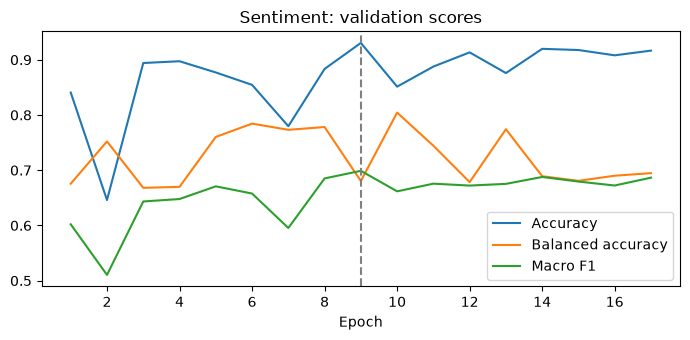

In [10]:
pd.DataFrame(sent_history).set_index('epoch')[['Accuracy', 'Balanced accuracy', 'Macro F1']].plot(figsize=(7, 3.5))
plt.axvline(sent_best_epoch, color='grey', linestyle='--')
plt.title('Sentiment: validation scores')
plt.xlabel('Epoch')
plt.tight_layout()
plt.show()

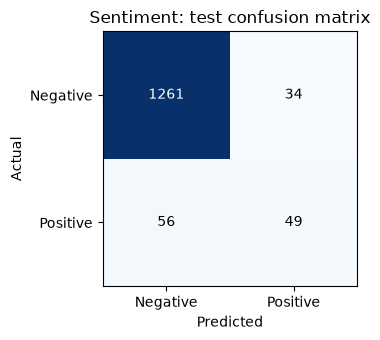

In [11]:
fig, ax = plt.subplots(figsize=(4, 3.5))
cm = sent_test_scores['Confusion matrix']
ax.imshow(cm, cmap='Blues')
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha='center', va='center', color='white' if value > cm.max()/2 else 'black')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Negative', 'Positive'],
       yticklabels=['Negative', 'Positive'], xlabel='Predicted', ylabel='Actual', title='Sentiment: test confusion matrix')
plt.tight_layout()
plt.show()

## **6. Read and split the captioning data**

Split by image (3,200 training, 400 validation, 400 test). All five captions remain with their image. Vocabulary is learned from training captions only.

In [12]:
captions_df = pd.read_csv('./data/team17/captions.csv')
names = sorted(Path('./data/team17/image_names.txt').read_text().splitlines())
random.Random(SEED).shuffle(names)
splits = {'train': names[:3200], 'validation': names[3200:3600], 'test': names[3600:]}

def caption_tokens(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

refs = {name: [caption_tokens(c) for c in group.caption] for name, group in captions_df.groupby('image')}
counts = Counter(word for name in splits['train'] for caption in refs[name] for word in caption)
words = ['<pad>', '<unk>', '<bos>', '<eos>'] + sorted(word for word, count in counts.items() if count >= 2)
cap_vocab = {word: i for i, word in enumerate(words)}
assert len(set(sum(splits.values(), []))) == 4000
display(captions_df.head())
print({split: len(names) for split, names in splits.items()})

,image,caption
0,1001773457_577c3a7d70.jpg,A black dog and a spotted dog are fighting
1,1001773457_577c3a7d70.jpg,A black dog and a tri-colored dog playing with...
2,1001773457_577c3a7d70.jpg,A black dog and a white dog with brown spots a...
3,1001773457_577c3a7d70.jpg,Two dogs of different breeds looking at each o...
4,1001773457_577c3a7d70.jpg,Two dogs on pavement moving toward each other .


{'train': 3200, 'validation': 400, 'test': 400}


## **7. Extract VGG16 image features**

Frozen ImageNet VGG16 convolutional features are globally averaged to 512 dimensions. Only training features determine normalization.

In [13]:
class Images(Dataset):
    def __init__(self, names, transform):
        self.names, self.transform = names, transform

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        with Image.open(DATA / 'images' / self.names[i]) as im:
            return self.transform(im.convert('RGB'))

encoder_device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
weights = VGG16_Weights.IMAGENET1K_V1
encoder = vgg16(weights=weights).features.eval().to(encoder_device)
all_names = sorted(sum(splits.values(), []))
image_loader = DataLoader(Images(all_names, weights.transforms()), batch_size=32, shuffle=False)
features = []
with torch.inference_mode():
    for batch in image_loader:
        features.append(encoder(batch.to(encoder_device)).mean(dim=(2, 3)).cpu())
features = torch.cat(features)
feature_map = dict(zip(all_names, features))
del encoder
print('VGG16 features:', features.shape, '| Device:', encoder_device)

VGG16 features: torch.Size([4000, 512]) | Device: mps


## **8. Build the caption decoder**

Project the image to 64 dimensions. Use it as the initial hidden state and concatenate it with each GloVe word vector. The decoder is one vanilla RNN layer with 64 units.

In [14]:
class Captions(Dataset):
    def __init__(self, names, refs, vocab, feature_map, max_length):
        self.rows = []
        for name in names:
            for caption in refs[name]:
                ids = [2] + [vocab.get(w, 1) for w in caption[:max_length-2]] + [3]
                ids += [0] * (max_length - len(ids))
                self.rows.append((feature_map[name], torch.tensor(ids)))

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        return self.rows[i]

class CaptionRNN(nn.Module):
    def __init__(self, embedding):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(embedding, freeze=False, padding_idx=0)
        self.image_projection = nn.Linear(512, 64)
        self.rnn = nn.RNN(50 + 64, 64, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.output = nn.Linear(64, len(embedding))
        self.register_buffer('feature_mean', torch.zeros(512))
        self.register_buffer('feature_std', torch.ones(512))

    def context(self, features):
        return torch.tanh(self.image_projection((features-self.feature_mean)/self.feature_std))

    def forward(self, features, ids):
        context = self.context(features)
        word = self.dropout(self.embedding(ids))
        inputs = torch.cat([word, context[:, None, :].expand(-1, ids.shape[1], -1)], dim=-1)
        hidden, _ = self.rnn(inputs, context.unsqueeze(0))
        return self.output(self.dropout(hidden))

set_seed()
cap_embeddings = glove_matrix(cap_vocab)
cap_model = CaptionRNN(cap_embeddings)
train_features = torch.stack([feature_map[name] for name in splits['train']])
cap_model.feature_mean.copy_(train_features.mean(0))
cap_model.feature_std.copy_(train_features.std(0).clamp_min(0.1))
cap_loaders = {
    split: DataLoader(Captions(splits[split], refs, cap_vocab, feature_map, 30),
                      batch_size=128, shuffle=(split == 'train'))
    for split in ['train', 'validation']
}
cap_model

GloVe coverage: 3287/3309 vocabulary words


CaptionRNN(
  (embedding): Embedding(3313, 50, padding_idx=0)
  (image_projection): Linear(in_features=512, out_features=64, bias=True)
  (rnn): RNN(114, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=64, out_features=3313, bias=True)
)

## **9. Train the caption model**

Teacher-forced token cross-entropy, Adam, gradient clipping and early stopping on validation loss.

In [15]:
def train_epoch(model, loader, optimizer=None):
    model.train(optimizer is not None)
    loss_sum, count = 0., 0
    for features, ids in loader:
        with torch.set_grad_enabled(optimizer is not None):
            logits = model(features, ids[:, :-1])
            targets = ids[:, 1:]
            loss = nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1), ignore_index=0)
            if optimizer is not None:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                optimizer.step()
        tokens = (targets != 0).sum().item()
        loss_sum += loss.item() * tokens
        count += tokens
    return loss_sum / count

optimizer = torch.optim.Adam(cap_model.parameters(), lr=0.002, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)
cap_history = []
best_loss, stale = float('inf'), 0
for epoch in range(1, 36):
    train_loss = train_epoch(cap_model, cap_loaders['train'], optimizer)
    val_loss = train_epoch(cap_model, cap_loaders['validation'])
    scheduler.step(val_loss)
    cap_history.append({'epoch': epoch, 'train_loss': train_loss, 'validation_loss': val_loss})
    print(f'Epoch {epoch:2d}: train={train_loss:.4f}, validation={val_loss:.4f}')
    if val_loss < best_loss - 0.001:
        best_loss, stale, cap_best_epoch = val_loss, 0, epoch
        cap_best_state = copy.deepcopy(cap_model.state_dict())
    else:
        stale += 1
    if stale >= 6:
        break
cap_model.load_state_dict(cap_best_state)
print('Selected epoch:', cap_best_epoch)

Epoch  1: train=5.4290, validation=4.5331


Epoch  2: train=4.3440, validation=3.9925


Epoch  3: train=3.9672, validation=3.7447


Epoch  4: train=3.7519, validation=3.5973


Epoch  5: train=3.5929, validation=3.4959


Epoch  6: train=3.4777, validation=3.4316


... (18 outputs left out)

Epoch 25: train=2.7597, validation=3.2245


Epoch 26: train=2.7192, validation=3.2215


Epoch 27: train=2.7053, validation=3.2237


Epoch 28: train=2.6954, validation=3.2246
Selected epoch: 22


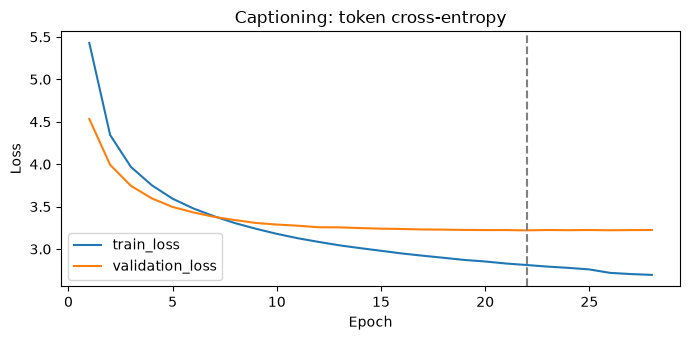

In [16]:
pd.DataFrame(cap_history).set_index('epoch')[['train_loss', 'validation_loss']].plot(figsize=(7, 3.5))
plt.axvline(cap_best_epoch, color='grey', linestyle='--')
plt.title('Captioning: token cross-entropy')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.tight_layout()
plt.show()

## **10. Generate captions and calculate BLEU**

Free-running beam search (width 3, length penalty 0.7), without reference captions as input. Report unsmoothed cumulative corpus BLEU-1–4 on the full training and test sets using all five references.

In [17]:
@torch.inference_mode()
def generate(model, features, max_length=30, beam_size=3):
    # Batched beam search: no reference captions or teacher forcing at inference.
    model.eval()
    context = model.context(features)
    batch = len(features)
    hidden = context[:, None, :].expand(-1, beam_size, -1).reshape(1, -1, 64).contiguous()
    context = context[:, None, :].expand(-1, beam_size, -1).reshape(-1, 64)
    sequences = torch.full((batch, beam_size, 1), 2, dtype=torch.long)
    scores = torch.full((batch, beam_size), -1e9)
    scores[:, 0] = 0
    ended = torch.zeros(batch, beam_size, dtype=torch.bool)
    lengths = torch.zeros(batch, beam_size)
    for _ in range(max_length - 1):
        token = sequences[:, :, -1].reshape(-1)
        inp = torch.cat([model.embedding(token), context], dim=-1).unsqueeze(1)
        output, next_hidden = model.rnn(inp, hidden)
        logits = model.output(output[:, 0]).reshape(batch, beam_size, -1)
        logits[:, :, :3] = -1e9
        logp = logits.log_softmax(-1)
        logp = logp.masked_fill(ended[:, :, None], -1e9)
        logp[:, :, 3] = torch.where(ended, torch.zeros_like(scores), logp[:, :, 3])
        candidate = scores[:, :, None] + logp
        next_lengths = lengths + (~ended).float()
        ranking = candidate / ((5 + next_lengths[:, :, None]) / 6).pow(0.7)
        _, indices = ranking.flatten(1).topk(beam_size, dim=1)
        source = indices // logits.shape[-1]
        new_token = indices % logits.shape[-1]
        scores = candidate.flatten(1).gather(1, indices)
        lengths = next_lengths.gather(1, source)
        ended = ended.gather(1, source) | (new_token == 3)
        sequences = torch.cat([sequences.gather(1, source[:, :, None].expand(-1, -1, sequences.shape[-1])), new_token[:, :, None]], -1)
        hidden = next_hidden.reshape(batch, beam_size, 64).gather(1, source[:, :, None].expand(-1, -1, 64)).reshape(1, -1, 64).contiguous()
        if ended.all():
            break
    best = (scores / ((5 + lengths) / 6).pow(0.7)).argmax(1)
    return sequences[torch.arange(batch), best].tolist()

In [18]:
@torch.inference_mode()
def evaluate(model, names, feature_map, refs, words):
    predictions = []
    for start in range(0, len(names), 128):
        batch = names[start:start+128]
        sequences = generate(model, torch.stack([feature_map[n] for n in batch]))
        for name, ids in zip(batch, sequences):
            tokens = []
            for idx in ids[1:]:
                if idx == 3:
                    break
                if idx >= 4:
                    tokens.append(words[idx])
            predictions.append(dict(image=name, generated=' '.join(tokens), references=[' '.join(r) for r in refs[name]]))
    references = [refs[p['image']] for p in predictions]
    hypotheses = [p['generated'].split() for p in predictions]
    scores = {f'BLEU@{k}': corpus_bleu(references, hypotheses, weights=tuple([1/k]*k)) for k in range(1,5)}
    return predictions, scores

cap_predictions, bleu = {}, {}
for split in ['train', 'test']:
    cap_predictions[split], bleu[split] = evaluate(cap_model, splits[split], feature_map, refs, words)
bleu_results = pd.DataFrame(bleu)
bleu_results.style.format('{:.4f}')

,train,test
BLEU@1,0.6626,0.5284
BLEU@2,0.4970,0.3494
BLEU@3,0.3557,0.2244
BLEU@4,0.2477,0.1425


## **11. Five training and five test examples**

Random selection with seed 17 from sorted filenames, without ranking. Show two ground-truth references and the unedited generated caption.

In [19]:
import textwrap

def show_examples(split):
    examples = random.Random(SEED).sample(sorted(cap_predictions[split], key=lambda row: row['image']), 5)
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), gridspec_kw={'width_ratios': [1, 2]})
    for row, example in enumerate(examples):
        with Image.open(DATA / 'images' / example['image']) as image:
            axes[row, 0].imshow(image)
        axes[row, 0].axis('off')
        lines = [f"{row+1}. {example['image']}"]
        lines += [textwrap.fill(f'Reference {i+1}: {ref}', 75) for i, ref in enumerate(example['references'][:2])]
        lines += [textwrap.fill('Generated: ' + example['generated'], 75)]
        axes[row, 1].text(0, 0.95, '\n'.join(lines), va='top', fontsize=10)
        axes[row, 1].axis('off')
    fig.suptitle(f'{split.title()} examples', fontsize=14)
    plt.tight_layout()
    plt.show()

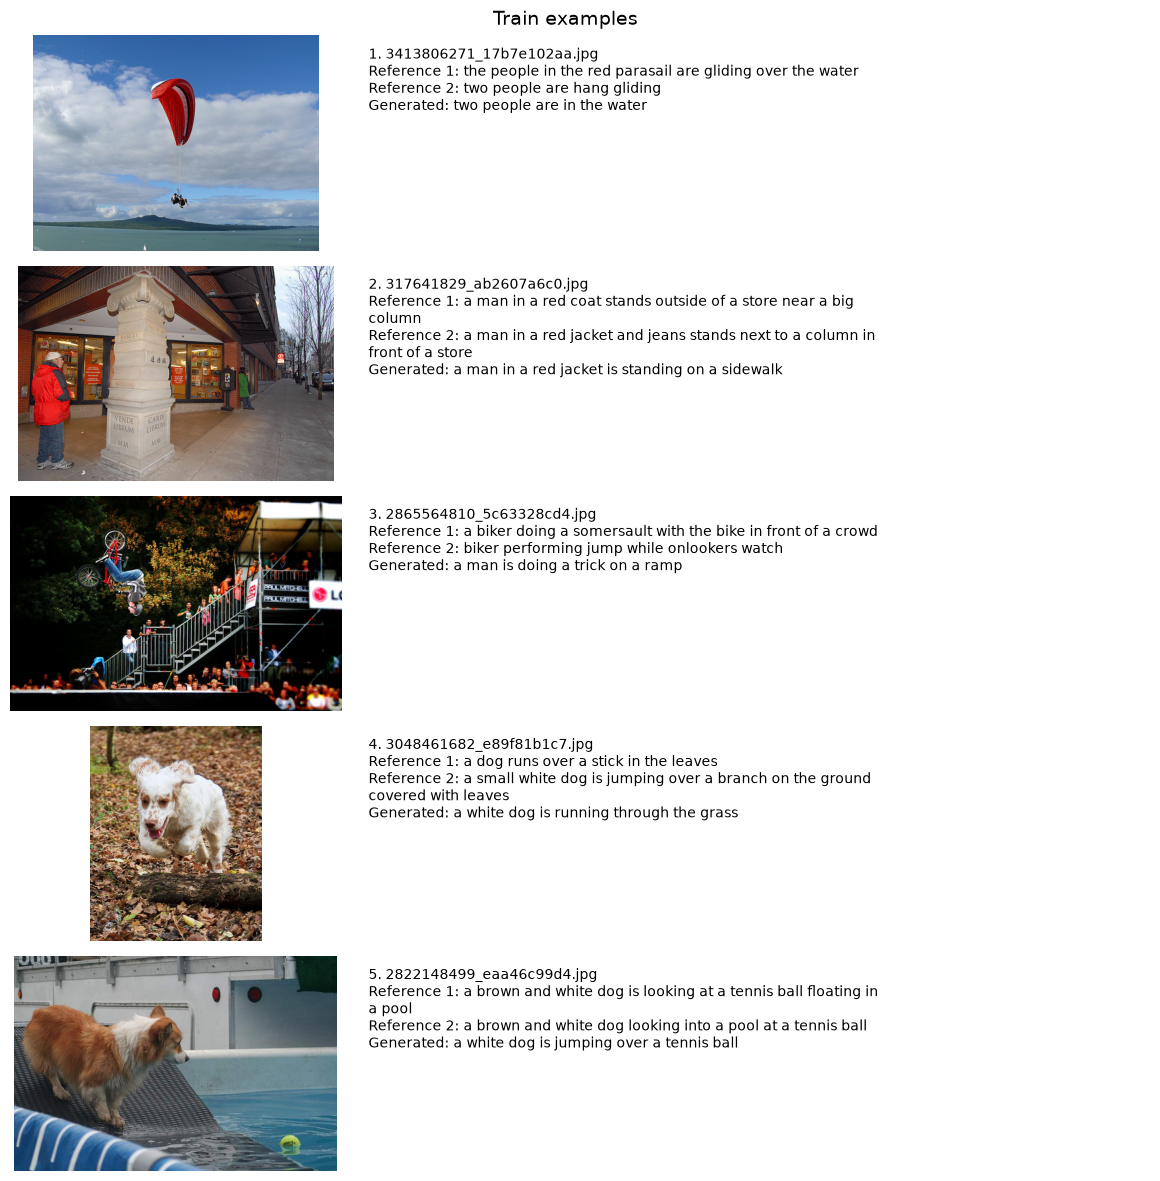

In [20]:
show_examples('train')

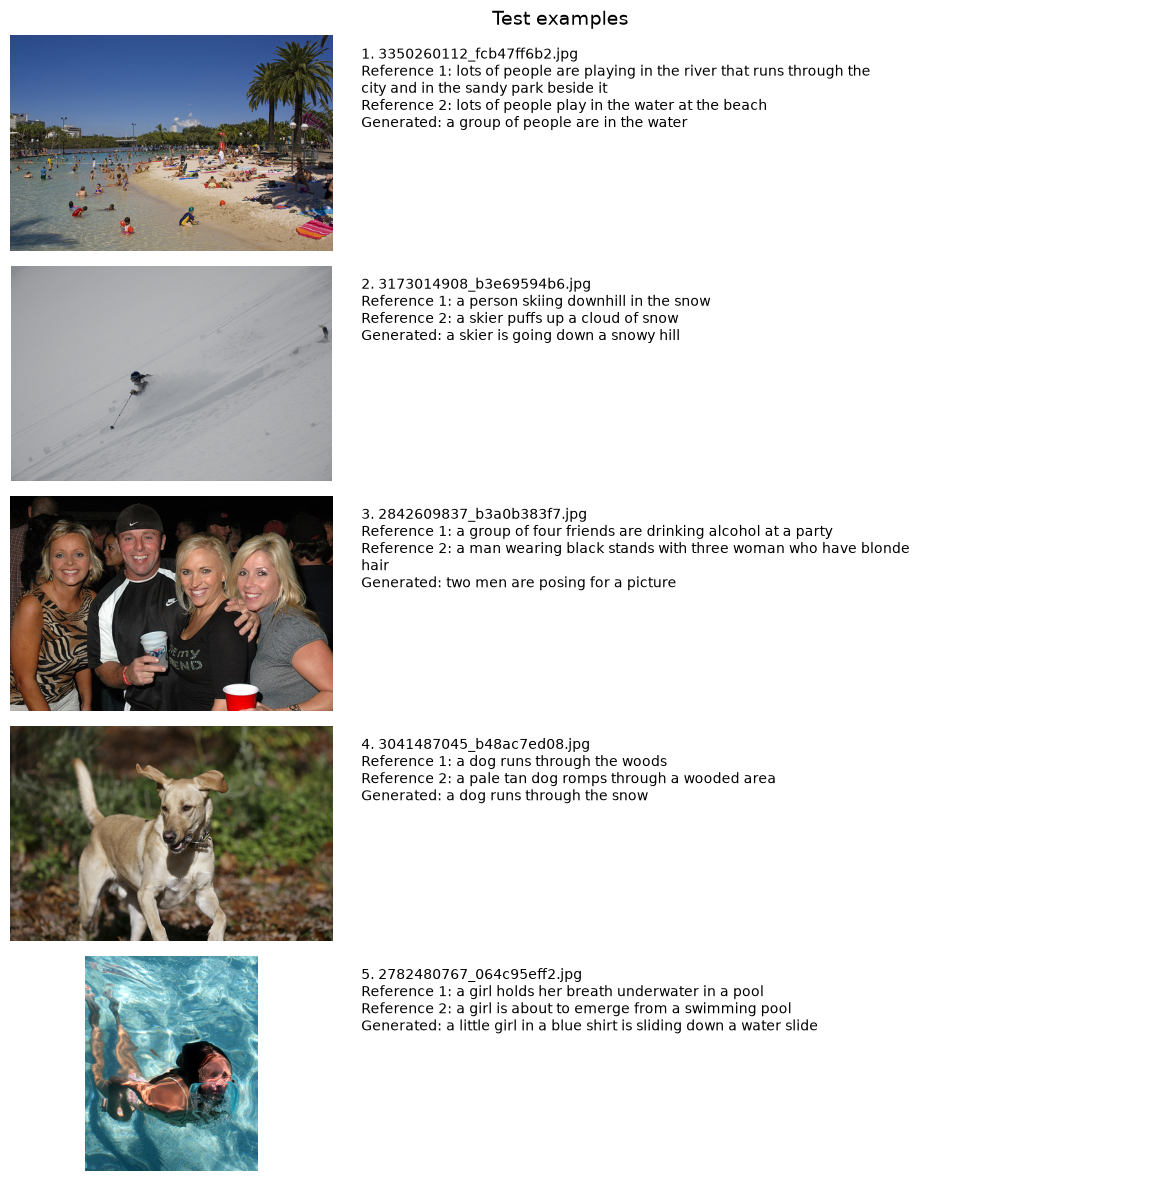

In [21]:
show_examples('test')

## **12. Results**

Accuracy is interpreted alongside the majority baseline and balanced accuracy because sentiment labels are imbalanced. Caption generation can recognize broad scenes but may confuse objects or omit details.

GloVe: Stanford GloVe 6B 50d (`./data/glove.6B.50d.txt`). VGG16: torchvision ImageNet-1K V1 weights. Dataset and pretrained downloads remain outside `submissions/`; the report is generated from `submissions/report.tex`.